# Lab 01 - Sentiment Analysis Using Traditional Machine Learning

**Module:** PUSL3205 - Large Language Models and Generative AI  
**Student Name:** Y.M.V.Gimhani  
**Student ID:** 10965223/33441

**Objective:** Practise basic NLP tasks - text preprocessing, Bag of Words / TF-IDF and training a machine learning model to classify sentences as positive or negative.

**Dataset:** [Sentiment Labelled Sentences - UCI](https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences) (Kotzias, 2015). Sentences from Amazon, IMDb and Yelp reviews, labelled `1` (positive) or `0` (negative).

## 0. Import Libraries

In [1]:
import re
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

nltk.download('stopwords', quiet=True)
sns.set_style('whitegrid')
pd.set_option('display.max_colwidth', 100)

RANDOM_STATE = 42          
SCREENSHOT_DIR = '../screenshots'

**Summary:** Loads all the tools needed for this lab - Pandas for working with the data, NLTK for the stopword list, Scikit-learn for building and evaluating the models, and Matplotlib/Seaborn for the charts. A fixed random seed is set so the results are the same every time the notebook is run.

## 1. Download and Load the Dataset

In [2]:
DATA_DIR = '../data'
files = {
    'Amazon': 'amazon_cells_labelled.txt',
    'IMDb': 'imdb_labelled.txt',
    'Yelp': 'yelp_labelled.txt',
}

frames = []
for source, file_name in files.items():
    # Each line is "sentence <tab> label".
    # quoting=3 (csv.QUOTE_NONE) stops pandas treating quote marks inside a
    # sentence as the start of a quoted field. Without it, rows get merged and
    # only 748 of the 1000 IMDb sentences are loaded.
    part = pd.read_csv(f'{DATA_DIR}/{file_name}', sep='\t', header=None,
                       names=['sentence', 'label'], quoting=3)
    part['source'] = source
    frames.append(part)
    print(f'{source}: {len(part)} rows')

df = pd.concat(frames, ignore_index=True)
print('Total rows:', len(df))
df.head()

Amazon: 1000 rows
IMDb: 1000 rows
Yelp: 1000 rows
Total rows: 3000


,sentence,label,source
0,So there is no way for me to plug it in here in the US unless I go by a converter.,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,Amazon
4,The mic is great.,1,Amazon


**Summary:** Reads the Amazon, IMDb and Yelp review files and combines them into one table, keeping a note of which website each sentence came from. `quoting=3` is needed because some IMDb sentences contain quote marks, which otherwise break the rows (only 748 of the 1,000 IMDb sentences load without it).

**Output:** 1,000 sentences were loaded from each source (3,000 in total). The first rows show each sentence with its label (1 = positive, 0 = negative) and its source.

In [3]:
# Basic checks on the combined data
print('Missing values:')
print(df.isnull().sum())
print('\nDuplicate sentences:', df.duplicated(subset='sentence').sum())
print('\nLabel counts:')
print(df['label'].value_counts())

Missing values:
sentence    0
label       0
source      0
dtype: int64

Duplicate sentences: 17

Label counts:
label
0    1500
1    1500
Name: count, dtype: int64


**Summary:** Checks the quality of the data before using it - whether any values are missing, whether any sentences are repeated, and whether the two classes are balanced.

**Output:** There are no missing values and 17 repeated sentences. There are exactly 1,500 positive and 1,500 negative sentences, so the dataset is balanced and the model will not be biased towards one class.

In [4]:

df = df.drop_duplicates(subset='sentence').reset_index(drop=True)
print('Rows after removing duplicates:', len(df))

Rows after removing duplicates: 2983


**Summary:** Removes the repeated sentences. If the same sentence ended up in both the training and test sets, the model would be tested on something it had already seen, which would make the score look better than it really is.

**Output:** 2,983 unique sentences remain.

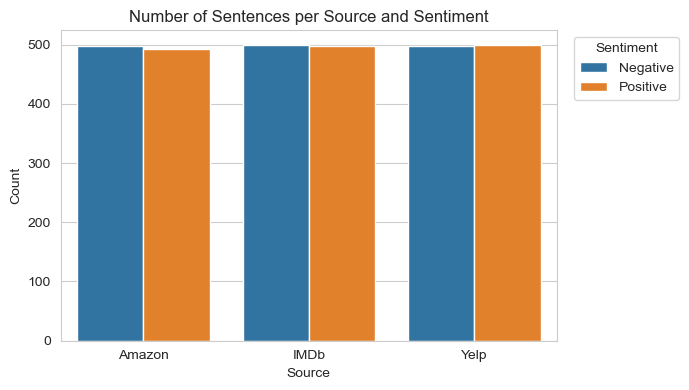

In [5]:
label_names = {0: 'Negative', 1: 'Positive'}

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='source', hue=df['label'].map(label_names))
plt.title('Number of Sentences per Source and Sentiment')
plt.xlabel('Source')
plt.ylabel('Count')
plt.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f'{SCREENSHOT_DIR}/label_distribution.png')
plt.show()

**Summary:** Plots how many positive and negative sentences come from each website.

**Output:** Each source has roughly 500 positive and 500 negative sentences, so no website or class dominates the data.

## 2. Text Preprocessing

- Convert text to lowercase
- Remove unnecessary characters and punctuation
- Remove extra whitespace
- Create a `clean_text` column
- Compare original and preprocessed text

In [6]:
def clean_text(text):
    """Lowercase the text and remove punctuation, numbers and extra whitespace."""
    text = text.lower()
    text = text.replace("'", '')              # "don't" -> "dont" so the negation stays one word
    text = re.sub(r'[^a-z\s]', ' ', text)     # replace anything that is not a letter with a space
    text = re.sub(r'\s+', ' ', text).strip()  # collapse repeated spaces and trim the ends
    return text

df['clean_text'] = df['sentence'].apply(clean_text)

**Summary:** Defines the cleaning steps and applies them to every sentence, saving the result in a new `clean_text` column. The text is made lowercase so that "Good" and "good" are treated as the same word, and punctuation, numbers and extra spaces are removed because they add noise without carrying sentiment. Apostrophes are removed first so negations like "don't" stay as one word ("dont") instead of being split into two.

In [7]:
# Compare original and cleaned text for a few random rows
df[['sentence', 'clean_text']].sample(8, random_state=RANDOM_STATE)

,sentence,clean_text
2410,We've tried to like this place but after 10+ times I think we're done with them.,weve tried to like this place but after times i think were done with them
1547,The script is a big flawed mess.,the script is a big flawed mess
881,It was that loud.Glad to say that the Plantronics 510 maintains a flawless connection to my cell...,it was that loud glad to say that the plantronics maintains a flawless connection to my cell and...
331,The reception is excellent!,the reception is excellent
1837,Now imagine that every single one of those decisions was made wrong.,now imagine that every single one of those decisions was made wrong
1242,The soundtrack sucked.,the soundtrack sucked
678,"This product is clearly not ready for prime time, I don't care how cool it looks, if you can't t...",this product is clearly not ready for prime time i dont care how cool it looks if you cant tell ...
1216,"He can bore you to pieces, and kill the momentum of a movie, quicker than anyone else.",he can bore you to pieces and kill the momentum of a movie quicker than anyone else


**Summary:** Shows original and cleaned sentences side by side to check that the cleaning worked correctly.

**Output:** The words and meaning of each sentence are kept, while capitals, punctuation and numbers are removed - for example "10+" disappears and "loud.Glad" becomes "loud glad".

In [8]:
# Check if any sentence became empty after cleaning (e.g. only punctuation)
print('Empty sentences after cleaning:', (df['clean_text'] == '').sum())
df = df[df['clean_text'] != ''].reset_index(drop=True)

Empty sentences after cleaning: 1


**Summary:** Checks whether any sentence became empty after cleaning and removes it, since an empty sentence gives the model nothing to learn from.

**Output:** One sentence contained no letters at all and was removed, leaving 2,982 sentences.

## 3. Explore the Text Data

### 3.1 Positive and Negative Examples

In [9]:
for label in [1, 0]:
    print(f'{label_names[label]} examples:')
    for sentence in df[df['label'] == label]['sentence'].head(5):
        print('  -', sentence)
    print()

Positive examples:
  - Good case, Excellent value.
  - Great for the jawbone.
  - The mic is great.
  - If you are Razr owner...you must have this!
  - And the sound quality is great.

Negative examples:
  - So there is no way for me to plug it in here in the US unless I go by a converter.
  - Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
  - I have to jiggle the plug to get it to line up right to get decent volume.
  - If you have several dozen or several hundred contacts, then imagine the fun of sending each of them one by one.
  - Needless to say, I wasted my money.



**Summary:** Prints a few positive and negative sentences to understand what the data looks like.

**Output:** Positive sentences use obvious words like "good", "great" and "excellent". Negative sentences often describe a problem ("I wasted my money") instead of using one clearly negative word, which makes them harder to classify.

### 3.2 Frequently Occurring Words

In [10]:
# remove stopwords only for counting words
# (not for the model - "not" and "no" are needed for sentiment)
stop_words = set(stopwords.words('english'))

def get_top_words(texts, n=15):
    words = [word for text in texts for word in text.split() if word not in stop_words]
    return Counter(words).most_common(n)

print('Top 15 words overall:')
print(get_top_words(df['clean_text']))

Top 15 words overall:
[('good', 231), ('great', 204), ('movie', 181), ('phone', 161), ('film', 160), ('one', 145), ('food', 125), ('like', 124), ('time', 112), ('place', 112), ('service', 108), ('bad', 103), ('really', 103), ('well', 96), ('would', 84)]


**Summary:** Counts the most common words across all reviews. Common filler words (stopwords such as "the" and "is") are ignored here so that the meaningful words stand out. They are not removed for the model, because the stopword list includes "not" and "no", which can change the sentiment of a sentence.

**Output:** The most common words are a mix of sentiment words (*good*, *great*, *bad*) and topic words (*movie*, *phone*, *food*).

### 3.3 Differences Between Positive and Negative Reviews

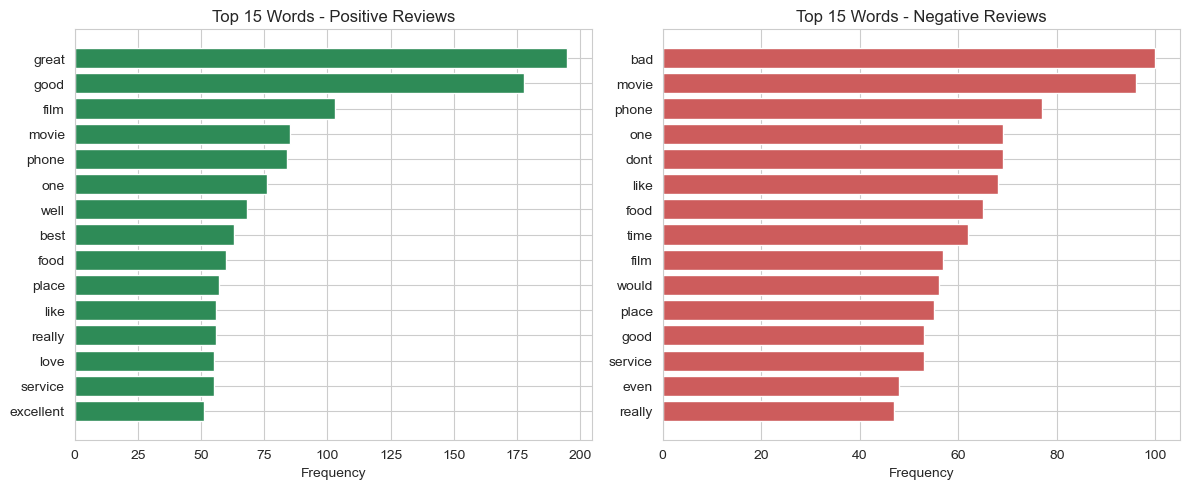

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, label, colour in zip(axes, [1, 0], ['seagreen', 'indianred']):
    top_words = get_top_words(df[df['label'] == label]['clean_text'])
    words, counts = zip(*top_words)
    ax.barh(words, counts, color=colour)
    ax.invert_yaxis()
    ax.set_title(f'Top 15 Words - {label_names[label]} Reviews')
    ax.set_xlabel('Frequency')

plt.tight_layout()
plt.savefig(f'{SCREENSHOT_DIR}/top_words.png')
plt.show()

**Summary:** Compares the most common words in positive and negative reviews side by side.

**Output:** Positive reviews are led by *great*, *good*, *best*, *love* and *excellent*, while negative reviews are led by *bad* and *dont*. Topic words like *movie*, *phone* and *food* appear in both lists, so they say nothing about sentiment. *good* also appears in negative reviews, most likely from phrases like "not good".

In [12]:
# Compare sentence length (number of words) between the two classes
df['word_count'] = df['clean_text'].str.split().str.len()
df.groupby(df['label'].map(label_names))['word_count'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Negative,1493.0,11.880107,7.582502,1.0,6.0,10.0,16.0,57.0
Positive,1489.0,11.841504,8.221096,1.0,6.0,10.0,16.0,73.0


**Summary:** Counts the number of words in each sentence to see whether positive and negative reviews differ in length.

**Output:** Both classes average about 12 words per sentence, so length cannot help predict sentiment - the model has to rely on the words themselves.

## 4. Split the Dataset

In [13]:
# 80% training / 20% testing.
# stratify keeps the same positive/negative ratio in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['label'],
    test_size=0.2, random_state=RANDOM_STATE, stratify=df['label'])

print('Training set:', len(X_train))
print('Test set:', len(X_test))
print('\nTraining label ratio:')
print(y_train.value_counts(normalize=True).round(3))

Training set: 2385
Test set: 597

Training label ratio:
label
0    0.501
1    0.499
Name: proportion, dtype: float64


**Summary:** Splits the data into 80% for training and 20% for testing. The test set is kept aside so the model can be evaluated on sentences it has never seen. `stratify` keeps the same positive/negative balance in both sets.

**Output:** 2,385 training sentences and 597 test sentences, with an almost exact 50/50 class ratio.

## 5. Create Bag of Words Representation

The vectorizers are fitted on the training set only, so no information from the test set leaks into the vocabulary. A TF-IDF version is also created to compare with plain word counts.

In [14]:
# Bag of Words: each sentence becomes a vector of word counts
bow_vectorizer = CountVectorizer()
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

print('Vocabulary size:', len(bow_vectorizer.vocabulary_))
print('BoW training matrix shape:', X_train_bow.shape)

Vocabulary size: 4460
BoW training matrix shape: (2385, 4460)


**Summary:** Converts the text into numbers using Bag of Words, because a model cannot work with raw text. Each sentence becomes a list of counts for every word in the vocabulary. The vocabulary is learned from the training set only, so nothing from the test set leaks into training.

**Output:** The vocabulary has 4,460 unique words, so each of the 2,385 training sentences is represented by 4,460 numbers.

In [15]:
# Example: the BoW vector for one training sentence (only non-zero entries shown)
example = X_train.iloc[0]
vector = bow_vectorizer.transform([example])
words = bow_vectorizer.get_feature_names_out()

print('Sentence:', example)
print({words[i]: int(vector[0, i]) for i in vector.nonzero()[1]})

Sentence: yes its that bad
{'bad': 1, 'its': 1, 'that': 1, 'yes': 1}


**Summary:** Shows what the Bag of Words representation looks like for one real sentence.

**Output:** "yes its that bad" becomes a count of 1 for each of its four words, and all the other 4,456 positions are zero. The word order is lost - only which words appear and how often is kept.

In [16]:
# TF-IDF: like BoW but common words across many sentences get a lower weight
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print('TF-IDF training matrix shape:', X_train_tfidf.shape)

TF-IDF training matrix shape: (2385, 4460)


**Summary:** Creates a second representation, TF-IDF, to compare with plain word counts. TF-IDF gives less weight to words that appear in many sentences and more weight to distinctive words, which can help the model focus on the useful ones.

**Output:** The TF-IDF matrix is the same size as Bag of Words (2,385 x 4,460), so the two can be compared fairly.

## 6. Train Machine Learning Models

Two models are trained on both feature types:
- **Logistic Regression**
- **Linear SVM**

In [17]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Linear SVM': LinearSVC(),
}
feature_sets = {
    'BoW': (bow_vectorizer, X_train_bow, X_test_bow),
    'TF-IDF': (tfidf_vectorizer, X_train_tfidf, X_test_tfidf),
}

trained = {}   # stores (vectorizer, model, predictions) for each combination
for feature_name, (vectorizer, X_tr, X_te) in feature_sets.items():
    for model_name, model in models.items():
        clf = clone(model)          # fresh copy so each combination is trained separately
        clf.fit(X_tr, y_train)
        trained[(feature_name, model_name)] = (vectorizer, clf, clf.predict(X_te))
        print(f'Trained: {model_name} + {feature_name}')

Trained: Logistic Regression + BoW
Trained: Linear SVM + BoW
Trained: Logistic Regression + TF-IDF
Trained: Linear SVM + TF-IDF


**Summary:** Trains two models - Logistic Regression and Linear SVM - on both Bag of Words and TF-IDF, giving four combinations to compare. Both are simple linear models that are fast and work well with large, sparse text data like this.

**Output:** All four combinations were trained successfully.

## 7. Evaluate the Models (Accuracy, Precision, Recall, F1)

In [18]:
results = []
for (feature_name, model_name), (_, _, y_pred) in trained.items():
    results.append({
        'Features': feature_name,
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False).reset_index(drop=True)
results_df.round(4)

,Features,Model,Accuracy,Precision,Recall,F1-Score
0,TF-IDF,Linear SVM,0.8074,0.8040,0.8121,0.8080
1,BoW,Linear SVM,0.7973,0.8000,0.7919,0.7960
2,BoW,Logistic Regression,0.7956,0.8034,0.7819,0.7925
3,TF-IDF,Logistic Regression,0.7873,0.7918,0.7785,0.7851


**Summary:** Tests each model on the unseen test set and measures Accuracy (how many predictions were correct), Precision (how many predicted positives were really positive), Recall (how many real positives were found) and F1-score (a balance of precision and recall).

**Output:** All four models score between 78.7% and 80.7% accuracy. Linear SVM + TF-IDF is the best with 80.7% accuracy and an F1-score of 0.808, although the differences between the models are small.

In [19]:
# Detailed report for the best combination (highest F1-score)
best_features, best_model_name = results_df.loc[0, ['Features', 'Model']]
best_vectorizer, best_model, best_pred = trained[(best_features, best_model_name)]

print(f'Best model: {best_model_name} + {best_features}\n')
print(classification_report(y_test, best_pred, target_names=['Negative', 'Positive']))

Best model: Linear SVM + TF-IDF

              precision    recall  f1-score   support

    Negative       0.81      0.80      0.81       299
    Positive       0.80      0.81      0.81       298

    accuracy                           0.81       597
   macro avg       0.81      0.81      0.81       597
weighted avg       0.81      0.81      0.81       597



**Summary:** Takes the best model and shows its scores for each class separately, to check that it performs equally well on positive and negative sentences.

**Output:** The scores are almost identical for both classes (0.80-0.81), so the model is not biased towards either sentiment.

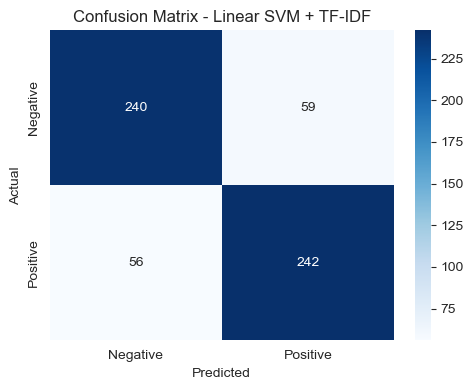

In [20]:
cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title(f'Confusion Matrix - {best_model_name} + {best_features}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(f'{SCREENSHOT_DIR}/confusion_matrix.png')
plt.show()

**Summary:** Draws a confusion matrix showing exactly where the best model was right and where it was wrong.

**Output:** 240 negative and 242 positive sentences were classified correctly. 59 negative sentences were wrongly predicted as positive and 56 positive sentences as negative, so the errors are spread evenly between the two classes.

In [21]:
# Which words does the model rely on most? (Logistic Regression + BoW coefficients)
_, lr_model, _ = trained[('BoW', 'Logistic Regression')]
coefs = pd.Series(lr_model.coef_[0], index=bow_vectorizer.get_feature_names_out())

print('Most positive words:', list(coefs.sort_values(ascending=False).head(10).index))
print('Most negative words:', list(coefs.sort_values().head(10).index))

Most positive words: ['great', 'love', 'good', 'excellent', 'loved', 'awesome', 'nice', 'delicious', 'amazing', 'fantastic']
Most negative words: ['bad', 'worst', 'not', 'poor', 'disappointment', 'terrible', 'awful', 'stupid', 'waste', 'fails']


**Summary:** Looks inside the Logistic Regression model to see which words push a prediction most strongly towards positive or negative.

**Output:** The model learned sensible words: *great*, *love* and *excellent* for positive, and *bad*, *worst* and *waste* for negative. *not* is one of the strongest negative words, which confirms that keeping stopwords for the model was the right choice.

In [22]:
# Look at some sentences the best model got wrong
test_results = pd.DataFrame({'sentence': X_test, 'actual': y_test, 'predicted': best_pred})
wrong = test_results[test_results['actual'] != test_results['predicted']]
print('Misclassified sentences:', len(wrong))
wrong.head(8)

Misclassified sentences: 115


,sentence,actual,predicted
985,the screen does get smudged easily because it touches your ear and face,0,1
1218,i was totally fascinated by the music the dancing everything,1,0
2056,the deal included tastings and drinks and jeff went above and beyond what we expected,1,0
1658,raw and sublimely moving,1,0
791,i tried talking real loud but shouting on the telephone gets old and i was still told it wasnt g...,0,1
2954,unfortunately it only set us up for disapppointment with our entrees,0,1
1381,having to humour him just to get by and get through the day was so apt,1,0
1132,you cant relate with them hell you barely can understand them,0,1


**Summary:** Lists the test sentences that the best model got wrong, to understand its weaknesses.

**Output:** 115 of the 597 test sentences were misclassified. Many errors contain rare words the model has hardly seen ("sublimely moving", "fascinated") or describe a problem without typical negative words ("the screen does get smudged easily").

## 8. Test the Model with New Sentences

In [23]:
def predict_sentiment(sentence, vectorizer=best_vectorizer, model=best_model):
    """Clean a new sentence, vectorize it and return the predicted sentiment."""
    vector = vectorizer.transform([clean_text(sentence)])
    return label_names[model.predict(vector)[0]]

new_sentences = [
    'The battery life of this phone is amazing!',
    'Worst customer service I have ever experienced.',
    'The movie was okay, nothing special.',
    'The food was not good at all.',
    'I did not expect it to be this good.',
    'Great, another phone that breaks after one week.',
]

for sentence in new_sentences:
    print(f'{predict_sentiment(sentence):<9} <- {sentence}')

Positive  <- The battery life of this phone is amazing!
Negative  <- Worst customer service I have ever experienced.
Negative  <- The movie was okay, nothing special.
Negative  <- The food was not good at all.
Negative  <- I did not expect it to be this good.
Negative  <- Great, another phone that breaks after one week.


**Summary:** Tests the best model on new sentences that are not in the dataset. Each sentence goes through the same cleaning and vectorizer as the training data, because the model only understands input in that format.

**Output:** Clear sentences were classified correctly, including "The food was not good at all." (negative). However, "I did not expect it to be this good." was wrongly predicted as negative, and the sarcastic sentence was most likely predicted negative because of the word *breaks*, not because the model understood the sarcasm. This shows the main weakness of Bag of Words: it ignores word order and context.

## Conclusion

In this lab I built a complete sentiment analysis pipeline using traditional machine learning: loading and cleaning the data, exploring word frequencies, converting text into BoW and TF-IDF features, and training and evaluating Logistic Regression and Linear SVM models. The best model (Linear SVM + TF-IDF) reached about 81% accuracy, which is good for such a simple approach. However, testing with new sentences showed that a Bag of Words model only counts words and does not understand word order, negation or sarcasm. This is the main limitation that transformer-based language models, covered in the later labs, are designed to address.

## References

- Kotzias, D. (2015) *Sentiment Labelled Sentences* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C57604
- Pedregosa, F. et al. (2011) 'Scikit-learn: Machine Learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825-2830.